# P2 프로젝트: 뉴스그룹 주제 분류

P2 실습에서는 Reuters 뉴스 기사를 이용하여
여러 클래스 중 하나를 예측하는 **다중 클래스 분류**를 다루었다.

이번 프로젝트에서는 새로운 텍스트 데이터인
**20 Newsgroups**를 이용하여 게시글의 주제를 분류한다.

프로젝트의 핵심은 Reuters 코드를 그대로 반복하는 것이 아니라,

> **새로운 다중 클래스 분류 문제에서 출력층·손실함수·평가지표를 선택하고, 일반화 성능과 오류를 판단하는 것**

이다.

**코드 실행**

[(구글 코랩) P2 프로젝트: 뉴스그룹 주제 분류](https://colab.research.google.com/github/codingalzi/code-workout-dlp/blob/master/P2_project_newsgroups.ipynb)에서 코드를 실행할 수 있다.

## 프로젝트에서 해야 할 일

1. 20개의 뉴스그룹 클래스와 데이터의 의미를 확인한다.
2. 제공된 텍스트 벡터화 결과를 확인한다.
3. 다중 클래스 분류에 적절한 모델을 설계한다.
4. **Keras와 PyTorch에서 모두** 기준 모델을 구성하고 훈련한다.
5. accuracy와 Top-3 accuracy를 함께 확인한다.
6. 두 프레임워크에서 과대적합 여부와 일반화 성능을 비교한다.
7. 각 프레임워크에서 일반화 성능을 개선하기 위한 방법을 하나 이상 적용한다.
8. Keras와 PyTorch의 최종 모델을 각각 테스트 데이터에서 평가한다.
9. 어떤 클래스들이 서로 혼동되는지 분석한다.

## 생성형 AI 활용

생성형 AI는 코드 작성·수정, 오류 메시지 해석,
Keras와 PyTorch 코드 변환, 그래프 작성,
모델 개선 방법이나 오류 분석 아이디어 제안 등에 활용할 수 있다.

하지만 다음은 직접 확인하고 판단해야 한다.

- 출력 유닛 수는 몇 개여야 하는가?
- 어떤 손실함수와 평가지표가 적절한가?
- accuracy와 Top-3 accuracy는 무엇을 다르게 보여주는가?
- Keras와 PyTorch에서 같은 다중 클래스 분류 문제를 어떻게 표현하는가?
- 모델 크기는 적절한가?
- 과대적합이 나타나는가?
- 두 프레임워크의 결과를 어떻게 비교할 것인가?
- 어떤 클래스들이 왜 서로 혼동되는가?

프로젝트 마지막에 **AI를 어디에 활용했고 무엇을 직접 검증했는지** 기록한다.

---

## 실행 환경 확인

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
import keras
import torch

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("PyTorch:", torch.__version__)
print("TensorFlow GPU:", tf.config.list_physical_devices("GPU"))
print("PyTorch CUDA:", torch.cuda.is_available())

TensorFlow: 2.21.0
Keras: 3.13.2
PyTorch: 2.11.0+cpu
TensorFlow GPU: []
PyTorch CUDA: False


---

## 20 Newsgroups 데이터

20 Newsgroups는 게시글을 **20개의 주제** 중 하나로 분류하는 데이터셋이다.

Reuters와 마찬가지로 여러 클래스 중 하나를 예측하지만,
이번에는 다른 텍스트 데이터에서 같은 원리를 적용한다.

원시 텍스트의 복잡한 전처리가 프로젝트의 중심이 되지 않도록
데이터 불러오기와 기본 벡터화 코드는 제공한다.

In [2]:
from sklearn.datasets import fetch_20newsgroups

newsgroups_train = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes"),
)

newsgroups_test = fetch_20newsgroups(
    subset="test",
    remove=("headers", "footers", "quotes"),
)

print("훈련 샘플 수:", len(newsgroups_train.data))
print("테스트 샘플 수:", len(newsgroups_test.data))
print("클래스 수:", len(newsgroups_train.target_names))

훈련 샘플 수: 11314
테스트 샘플 수: 7532
클래스 수: 20


### 클래스 확인

In [3]:
for i, name in enumerate(newsgroups_train.target_names):
    print(f"{i:2d}: {name}")

 0: alt.atheism
 1: comp.graphics
 2: comp.os.ms-windows.misc
 3: comp.sys.ibm.pc.hardware
 4: comp.sys.mac.hardware
 5: comp.windows.x
 6: misc.forsale
 7: rec.autos
 8: rec.motorcycles
 9: rec.sport.baseball
10: rec.sport.hockey
11: sci.crypt
12: sci.electronics
13: sci.med
14: sci.space
15: soc.religion.christian
16: talk.politics.guns
17: talk.politics.mideast
18: talk.politics.misc
19: talk.religion.misc


### 게시글 하나 확인

In [4]:
sample_index = 0

print("정답 클래스:", newsgroups_train.target[sample_index])
print("클래스 이름:", newsgroups_train.target_names[newsgroups_train.target[sample_index]])
print()
print(newsgroups_train.data[sample_index][:1500])

정답 클래스: 7
클래스 이름: rec.autos

I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### 문제 1 — Reuters와 무엇이 같고 다른가?

1. 이 문제는 왜 다중 클래스 분류인가?
2. 한 게시글은 여러 주제에 동시에 속하는가, 하나의 주제에 속하는가?
3. 출력층의 유닛 수는 몇 개가 되어야 하는가?
4. Reuters 문제와 공통점과 차이점을 설명하라.

**답:**

> 1. 분류하려는 글이 어느 클래스에 속하는지 20개의 클래스에서 분류해야 하기 때문에
2. 하나에 속한다
3. 다중 클래스 분류에서 출력층의 유닛 수는 카테고리의 전체 개수와 같아야 한다. 따라서 20 Newsgroups 데이터셋의 데이터(클래스) 20개 각각에 대한 예측 점수를 내놓아야 하므로 출력층의 유닛 수는 20개가 되어야 한다.
4. 공통점: 단일 라벨 다중 클래스 분류라는 문제 유형, 텍스트 벡터화, 출력층과 손실함수의 구조, 평가지표 / 차이점: 분류하려는 카테고리의 개수, 데이터의 특성, 입력 차원 및 데이터 크기

---

## 훈련셋과 검증셋 분리

원래의 테스트 데이터는 **최종 평가**에만 사용한다.

훈련 데이터의 일부를 검증셋으로 분리하여
모델 구조와 일반화 성능을 판단한다.

클래스 비율이 크게 달라지지 않도록 `stratify`를 사용한다.

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

train_texts, val_texts, y_train, y_val = train_test_split(
    newsgroups_train.data,
    newsgroups_train.target,
    test_size=0.2,
    random_state=42,
    stratify=newsgroups_train.target,
)

test_texts = newsgroups_test.data
y_test = np.asarray(newsgroups_test.target, dtype="int64")

y_train = np.asarray(y_train, dtype="int64")
y_val = np.asarray(y_val, dtype="int64")

print("train:", len(train_texts))
print("validation:", len(val_texts))
print("test:", len(test_texts))

train: 9051
validation: 2263
test: 7532


---

## 텍스트 벡터화

신경망의 Dense 층은 문자열을 직접 입력으로 사용할 수 없다.
따라서 게시글을 고정 길이의 수치 벡터로 변환한다.

이번 프로젝트에서는 **TF-IDF** 벡터화를 제공한다.

프로젝트의 초점은 벡터화 방법 자체보다
**다중 클래스 모델을 설계하고 평가하는 것**이다.

중요한 점은 벡터화 기준도 훈련 데이터에서만 학습해야 한다는 것이다.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=3000,
    stop_words="english",
    dtype=np.float32,
)

X_train_sparse = vectorizer.fit_transform(train_texts)
X_val_sparse = vectorizer.transform(val_texts)
X_test_sparse = vectorizer.transform(test_texts)

X_train = X_train_sparse.toarray()
X_val = X_val_sparse.toarray()
X_test = X_test_sparse.toarray()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (9051, 3000)
X_val: (2263, 3000)
X_test: (7532, 3000)


### 벡터화 확인

1. 한 게시글이 몇 개의 입력값으로 표현되는가?
2. 모든 게시글의 원래 길이가 다른데도 Dense 층에 넣을 수 있는 이유는 무엇인가?
3. `fit_transform()`은 훈련 텍스트에만 사용하고 검증·테스트에는 `transform()`만 사용하는 이유는 무엇인가?

**답:**

> 1. 3,000개의 입력값
2. 모두 고정 길이의 수치 벡터로 변환하였기 때문이다.
3. 데이터 누수 방지 및 실제 환경과 동일한 조건을 유지하기 위함

---

## 모델링

이번 프로젝트에서는 **Keras와 PyTorch를 모두 사용한다.**

Reuters 실습의 모델은 좋은 출발점이지만,
이번에는 입력 차원과 클래스 수가 다르다.

가능하면 두 프레임워크에서 비슷한 은닉층 구조를 사용하여
같은 다중 클래스 분류 원리가 어떻게 표현되는지 비교한다.

다음 사항을 직접 결정한다.

- 은닉층 수
- 각 은닉층의 유닛 수
- Dropout 또는 L2 규제 사용 여부
- batch size
- 최대 epoch
- 조기 종료 사용 여부

### 공통 모델 설계 원칙

Keras와 PyTorch에서 가능한 한 비슷한 구조를 사용한다.

- 은닉층 수:
- 각 은닉층의 유닛 수:
- 클래스 수:
- 출력층 유닛 수:
- 손실함수:
- 기본 평가지표:
- 추가 Top-k 지표:
- batch size:
- 최대 epoch:

**이 구조를 선택한 이유:**

> 1: 3개의 은닉층
> 2: 128, 64개
> 3: 20개
> 4: 20개
> 5: Keras - sparse_categorical_crossentropy / PyTorch -  nn.CrossEntropyLoss()
> 6: accuracy
> 7: Top-3 accuracy
> 8: 256
> 9: 15 epoch

### Keras와 PyTorch에서 출력이 다른 점

같은 다중 클래스 분류 문제라도 구현 방식에는 차이가 있다.

- Keras에서는 보통 마지막 층에 `softmax`를 두어 확률 분포를 출력한다.
- PyTorch에서는 보통 마지막 층에서 **logits**를 출력하고 `CrossEntropyLoss()`가 필요한 계산을 내부적으로 처리한다.

따라서 두 모델의 마지막 코드 모양은 다르지만
**20개 클래스 중 하나를 예측한다는 문제 자체는 동일하다.**

> 두 구현이 어떻게 대응되는지 프로젝트를 진행하면서 확인한다.

---

## Keras 모델

먼저 Keras에서 기준 모델과 개선 모델을 구성하고 훈련한다.

### Keras 기준 모델

In [8]:
from keras import layers

num_classes = len(newsgroups_train.target_names)

keras_base = keras.Sequential([
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

keras_base.build(input_shape=(None, X_train.shape[1]))
keras_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       384,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │           660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 395,124 (1.51 MB)

 Trainable params: 395,124 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# TODO: Top-3 accuracy를 포함하여 compile하고 훈련한다.
top_3_accuracy = keras.metrics.SparseTopKCategoricalAccuracy(
    k=3,
    name="top_3_accuracy"
)

keras_base.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", top_3_accuracy]
)

history_base = keras_base.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=256,
    validation_data=(X_val, y_val),
    verbose=1,
)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.1672 - loss: 2.9445 - top_3_accuracy: 0.3306 - val_accuracy: 0.3018 - val_loss: 2.7959 - val_top_3_accuracy: 0.5236
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4132 - loss: 2.3948 - top_3_accuracy: 0.6175 - val_accuracy: 0.4719 - val_loss: 1.9776 - val_top_3_accuracy: 0.7057
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6205 - loss: 1.4965 - top_3_accuracy: 0.8259 - val_accuracy: 0.6045 - val_loss: 1.4113 - val_top_3_accuracy: 0.7967
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7229 - loss: 1.0181 - top_3_accuracy: 0.8873 - val_accuracy: 0.6235 - val_loss: 1.2778 - val_top_3_accuracy: 0.8100
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.7764 - loss: 0.7937 - top_3_accuracy: 0.9189 - val_accuracy: 0.6293 - val_loss: 1.2482 - val_top_3_accuracy: 0.8073
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8200 - loss: 0.6498 - top_3_ac

### Keras 개선 모델

기준 모델의 훈련·검증 결과를 확인한 뒤
다음 방법 중 하나 이상을 적용한다.

- 은닉층 크기 변경
- L2 가중치 규제
- Dropout
- EarlyStopping

**변경 내용과 이유:**

> 변경 내용: Dropout 0.4 적용 / 이유: 학습 흐름을 인위적으로 끊거나(조기종료) 가중치 업데이트에 직접적 패널티(L2 규제)를 주지 않고, 학습 자체의 효과와 성능을 개선하기 위해.

In [10]:
from keras import layers

keras_improved_04 = keras.Sequential([
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax")
])

improved_model = keras_improved_04

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top_3_accuracy")]
)

history_improved = improved_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=256,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.0663 - loss: 2.9871 - top_3_accuracy: 0.1929 - val_accuracy: 0.1794 - val_loss: 2.9621 - val_top_3_accuracy: 0.4030
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.1279 - loss: 2.8939 - top_3_accuracy: 0.3042 - val_accuracy: 0.3407 - val_loss: 2.7131 - val_top_3_accuracy: 0.5550
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.2138 - loss: 2.5913 - top_3_accuracy: 0.4500 - val_accuracy: 0.4653 - val_loss: 2.2438 - val_top_3_accuracy: 0.6871
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.3157 - loss: 2.2145 - top_3_accuracy: 0.5882 - val_accuracy: 0.5475 - val_loss: 1.8402 - val_top_3_accuracy: 0.7645
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.4070 - loss: 1.9222 - top_3_accuracy: 0.6798 - val_accuracy: 0.5824 - val_loss: 1.6092 - val_top_3_accuracy: 0.7861
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.4612 - loss: 1.7262 - top_3_ac

---

## PyTorch 모델

같은 다중 클래스 분류 문제를 PyTorch에서도 구현한다.
가능하면 Keras 모델과 비슷한 은닉층 구조를 사용한다.

In [16]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)
test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.long)
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

print("device:", device)

device: cpu


### PyTorch 훈련 함수

PyTorch에서는 모델이 **logits**를 출력하고
`CrossEntropyLoss()`가 softmax에 해당하는 계산을 내부적으로 처리한다.

프로젝트의 중심이 반복문 작성이 되지 않도록 기본 훈련 함수를 제공한다.

In [17]:
def evaluate_multiclass(model, loader):
    model.eval()

    loss_fn = nn.CrossEntropyLoss()
    total_loss = 0.0
    correct = 0
    top3_correct = 0
    total = 0

    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(x_batch)
            loss = loss_fn(logits, y_batch)

            total_loss += loss.item() * len(x_batch)
            correct += (logits.argmax(dim=1) == y_batch).sum().item()

            top3 = logits.topk(3, dim=1).indices
            top3_correct += (top3 == y_batch.unsqueeze(1)).any(dim=1).sum().item()
            total += len(x_batch)

    return {
        "loss": total_loss / total,
        "accuracy": correct / total,
        "top_3_accuracy": top3_correct / total,
    }


def train_multiclass_model(model, train_loader, val_loader, epochs=20,
                           weight_decay=0.0, patience=None):
    model = model.to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        weight_decay=weight_decay
    )

    history = {
        "loss": [], "val_loss": [],
        "accuracy": [], "val_accuracy": [],
        "top_3_accuracy": [], "val_top_3_accuracy": []
    }

    best_val_loss = float("inf")
    best_state = None
    wait = 0

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        correct = 0
        top3_correct = 0
        total = 0

        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            logits = model(x_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(x_batch)
            correct += (logits.argmax(dim=1) == y_batch).sum().item()
            top3 = logits.topk(3, dim=1).indices
            top3_correct += (top3 == y_batch.unsqueeze(1)).any(dim=1).sum().item()
            total += len(x_batch)

        train_loss = total_loss / total
        train_acc = correct / total
        train_top3 = top3_correct / total

        val_result = evaluate_multiclass(model, val_loader)

        history["loss"].append(train_loss)
        history["accuracy"].append(train_acc)
        history["top_3_accuracy"].append(train_top3)
        history["val_loss"].append(val_result["loss"])
        history["val_accuracy"].append(val_result["accuracy"])
        history["val_top_3_accuracy"].append(val_result["top_3_accuracy"])

        if patience is not None:
            if val_result["loss"] < best_val_loss:
                best_val_loss = val_result["loss"]
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history

### PyTorch 기준 모델

In [18]:
num_classes = len(newsgroups_train.target_names)

torch_base = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, num_classes)
).to(device)

torch_base, torch_history_base = train_multiclass_model(
    model=torch_base,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15
)

In [20]:
# PyTorch 기준 모델의 훈련 결과 출력해보기
for epoch, (t_loss, t_acc, v_loss, v_acc) in enumerate(zip(
    torch_history_base["loss"],
    torch_history_base["accuracy"],
    torch_history_base["val_loss"],
    torch_history_base["val_accuracy"]
), 1):
    print(f"Epoch {epoch:2d}/15 - Loss: {t_loss:.4f} - Acc: {t_acc:.4f} | Val Loss: {v_loss:.4f} - Val Acc: {v_acc:.4f}")

Epoch  1/15 - Loss: 2.9517 - Acc: 0.0914 | Val Loss: 2.7727 - Val Acc: 0.2201
Epoch  2/15 - Loss: 2.2167 - Acc: 0.3568 | Val Loss: 1.7822 - Val Acc: 0.4693
Epoch  3/15 - Loss: 1.3713 - Acc: 0.6028 | Val Loss: 1.5034 - Val Acc: 0.5643
Epoch  4/15 - Loss: 1.0446 - Acc: 0.6901 | Val Loss: 1.4628 - Val Acc: 0.5820
Epoch  5/15 - Loss: 0.8917 - Acc: 0.7286 | Val Loss: 1.5068 - Val Acc: 0.5802
Epoch  6/15 - Loss: 0.7912 - Acc: 0.7569 | Val Loss: 1.5755 - Val Acc: 0.5771
Epoch  7/15 - Loss: 0.7083 - Acc: 0.7852 | Val Loss: 1.6564 - Val Acc: 0.5767
Epoch  8/15 - Loss: 0.6359 - Acc: 0.8114 | Val Loss: 1.7475 - Val Acc: 0.5709
Epoch  9/15 - Loss: 0.5782 - Acc: 0.8312 | Val Loss: 1.8484 - Val Acc: 0.5656
Epoch 10/15 - Loss: 0.5232 - Acc: 0.8490 | Val Loss: 1.9862 - Val Acc: 0.5656
Epoch 11/15 - Loss: 0.4766 - Acc: 0.8669 | Val Loss: 2.0900 - Val Acc: 0.5674
Epoch 12/15 - Loss: 0.4288 - Acc: 0.8854 | Val Loss: 2.2116 - Val Acc: 0.5665
Epoch 13/15 - Loss: 0.3859 - Acc: 0.9013 | Val Loss: 2.3611 - Va

### PyTorch 개선 모델

**변경 내용과 이유:**

> 변경 내용: Dropout 0.4 적용 / 이유: 훈련셋에 대한 과대적합 방지

In [21]:
torch_improved = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(32, num_classes)
).to(device)

torch_improved, torch_history_improved = train_multiclass_model(
    model=torch_improved,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15,
    weight_decay=0.0,
    patience=None
)

In [25]:
# PyTorch 개선 모델(Dropout 0.4)의 결과 출력
print("=== PyTorch 개선 모델 훈련 결과 (Dropout 0.4) ===")
for epoch, (t_loss, t_acc, v_loss, v_acc) in enumerate(zip(
    torch_history_improved['loss'],
    torch_history_improved['accuracy'],
    torch_history_improved['val_loss'],
    torch_history_improved['val_accuracy']
), 1):
    print(f"Epoch {epoch:2d}/15 - Loss: {t_loss:.4f} - Acc: {t_acc:.4f} | Val Loss: {v_loss:.4f} - Val Acc: {v_acc:.4f}")

=== PyTorch 개선 모델 훈련 결과 (Dropout 0.4) ===
Epoch  1/15 - Loss: 2.9926 - Acc: 0.0672 | Val Loss: 2.9446 - Val Acc: 0.1144
Epoch  2/15 - Loss: 2.6801 - Acc: 0.1416 | Val Loss: 2.3254 - Val Acc: 0.2435
Epoch  3/15 - Loss: 2.2415 - Acc: 0.2287 | Val Loss: 2.0095 - Val Acc: 0.3624
Epoch  4/15 - Loss: 1.9940 - Acc: 0.3007 | Val Loss: 1.8277 - Val Acc: 0.4551
Epoch  5/15 - Loss: 1.8051 - Acc: 0.3670 | Val Loss: 1.7053 - Val Acc: 0.4728
Epoch  6/15 - Loss: 1.6421 - Acc: 0.4137 | Val Loss: 1.6208 - Val Acc: 0.5099
Epoch  7/15 - Loss: 1.5201 - Acc: 0.4675 | Val Loss: 1.5747 - Val Acc: 0.5068
Epoch  8/15 - Loss: 1.4003 - Acc: 0.5076 | Val Loss: 1.5381 - Val Acc: 0.5457
Epoch  9/15 - Loss: 1.3118 - Acc: 0.5481 | Val Loss: 1.5261 - Val Acc: 0.5559
Epoch 10/15 - Loss: 1.2351 - Acc: 0.5712 | Val Loss: 1.5336 - Val Acc: 0.5515
Epoch 11/15 - Loss: 1.1596 - Acc: 0.6047 | Val Loss: 1.5280 - Val Acc: 0.5736
Epoch 12/15 - Loss: 1.0949 - Acc: 0.6315 | Val Loss: 1.5564 - Val Acc: 0.5683
Epoch 13/15 - Loss: 1.

---

## 훈련 과정 확인

기준 모델과 개선 모델의 훈련·검증 결과를 비교한다.

특히 다음 세 가지를 함께 살펴본다.

- loss
- accuracy
- Top-3 accuracy

In [26]:
# Keras
keras_base_history = history_base.history
keras_improved_history = history_improved.history

# PyTorch
pytorch_base_history = torch_history_base
pytorch_improved_history = torch_history_improved

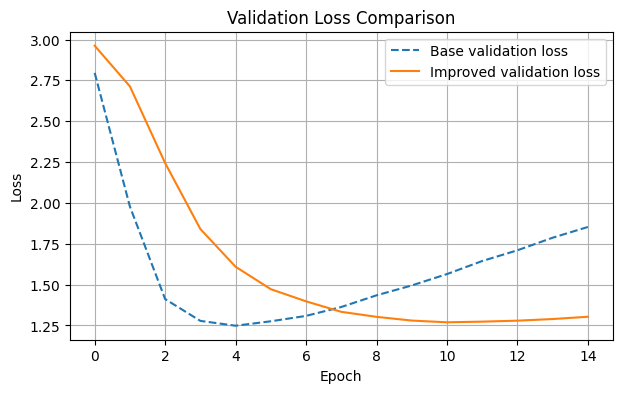

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(keras_base_history["val_loss"], label="Base validation loss", linestyle="--")
plt.plot(keras_improved_history["val_loss"], label="Improved validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

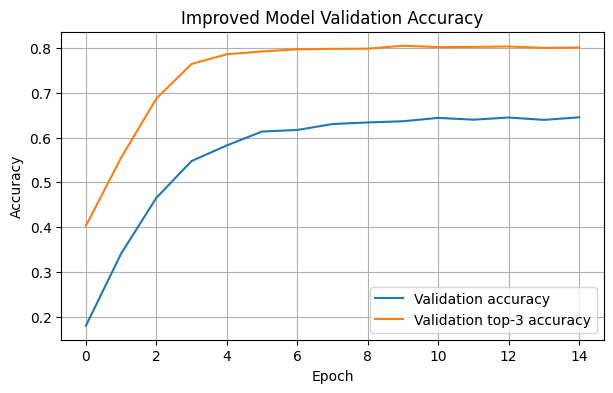

In [28]:
plt.figure(figsize=(7, 4))
plt.plot(keras_improved_history["val_accuracy"], label="Validation accuracy")
plt.plot(keras_improved_history["val_top_3_accuracy"], label="Validation top-3 accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved Model Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### 결과 비교와 모델 선택

다음 질문에 답한다.

1. Keras에서 훈련 loss와 검증 loss는 어떻게 변화했는가?
2. PyTorch에서 훈련 loss와 검증 loss는 어떻게 변화했는가?
3. 각 프레임워크에서 과대적합이 나타났는가?
4. 기준 모델과 개선 모델의 검증 accuracy는 어떻게 달라졌는가?
5. Top-3 accuracy는 일반 accuracy보다 왜 높은가?
6. Keras와 PyTorch의 검증 accuracy와 Top-3 accuracy는 얼마나 비슷하거나 달랐는가?
7. 같은 구조를 사용했는데도 결과가 다르다면 가능한 이유는 무엇인가?
8. 각 프레임워크에서 최종 모델로 어떤 모델을 선택하겠는가?

**답:**

> 1. 기준 모델에서의 훈련 손실은 0.1746까지 감소했으나 검증 손실은 에포크5(1.2382)이후로 치솟아 최종적으로 1.8527로 마무리하였고, 드롭아웃을 적용한 모델에서는 검증 손실이 1.3031 수준을 유지함.
2. 기준 모델에서의 훈련 손실은 0.9242까지 감소했으나 검증 손실은 에포크5(1.5068)이후로 치솟아 2.6701로 마무리하였고, 드롭아웃을 적용한 모델에서는 검증 손실이 1.6207 수준을 유지함.
3. 에포크 15 기준, Keras에서는 36.35%(훈련 정확도 96.40%-검증 정확도 60.05%)의 격차가 발생했으며, PyTorch에서는 37.85%(훈련 정확도 92.42%-검증 정확도 54.57%)의 격차가 발생하여 과대적합이 발생하였음.
4. Keras에서는 60.05%에서 64.52%로, PyTorch에서는 54.57%에서 58.15%로 상승함.
5. Top-1 Accuracy는 가장 높은 확률로 예측한 1위 정답만 인정하지만, Top-3 Accuracy는 가장 높은 3개의 카테고리 중 하나라도 일치하면 정답으로 판정하기 때문이다.
6. 두 프레임워크 모두 드롭아웃 적용 후 과대적합 해소 및 정확도 상승은 동일하였으나, 최종적인 수치는 Keras 개선 모델이 가장 높았음.
7. Keras와 PyTorch의 가중치 초기화 방식, 내부 연산 구현 방식, 데이터 로직 및 미니배치 구성 순서 등의 차이가 존재하기 때문.
8. Keras와 PyTorch 모두 개선 모델을 선택. 두 프레임워크 모두 개선 이후 검증률과 손실률이 눈에 띄게 개선되었고 안정적이기 때문이다.

---

## 최종 테스트 평가

모델 비교가 끝난 뒤
**Keras와 PyTorch에서 선택한 최종 모델을 각각**
테스트 데이터에서 한 번 평가한다.

In [29]:
# Keras 최종 모델 (드롭아웃이 적용된 improved_model 사용)
keras_final_model = improved_model

keras_results = keras_final_model.evaluate(
    X_test, y_test, verbose=0
)

print("Keras test loss:", keras_results[0])
print("Keras test accuracy:", keras_results[1])
print("Keras test top-3 accuracy:", keras_results[2])

Keras test loss: 1.523058295249939
Keras test accuracy: 0.5819171667098999
Keras test top-3 accuracy: 0.7657992839813232


In [30]:
test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.long)
)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# PyTorch 최종 모델 (드롭아웃이 적용된 torch_improved 사용)
pytorch_final_model = torch_improved

pytorch_test_result = evaluate_multiclass(
    pytorch_final_model,
    test_loader
)

print("PyTorch test result:", pytorch_test_result)

PyTorch test result: {'loss': 1.937116148430049, 'accuracy': 0.5288104089219331, 'top_3_accuracy': 0.7380509824747743}


---

## 예측 결과와 오류 분석

전체 accuracy만으로는 어떤 주제들이 서로 혼동되는지 알 수 없다.

최종 모델의 예측 클래스 번호를 만들고,
**혼동행렬**과 오분류 사례를 확인한다.

In [31]:
# Keras 최종 모델의 테스트 예측
keras_probabilities = keras_final_model.predict(X_test, verbose=0)
keras_predictions = keras_probabilities.argmax(axis=1)

# PyTorch 최종 모델의 테스트 예측
pytorch_final_model.eval()
preds = []

with torch.no_grad():
    for x_batch, _ in test_loader:
        logits = pytorch_final_model(x_batch.to(device))
        preds.append(logits.argmax(dim=1).cpu().numpy())

pytorch_predictions = np.concatenate(preds)

In [32]:
# 두 프레임워크의 혼동행렬을 계산한다.
from sklearn.metrics import confusion_matrix

keras_cm = confusion_matrix(y_test, keras_predictions)
pytorch_cm = confusion_matrix(y_test, pytorch_predictions)

print("Keras confusion matrix:", keras_cm.shape)
print("PyTorch confusion matrix:", pytorch_cm.shape)

Keras confusion matrix: (20, 20)
PyTorch confusion matrix: (20, 20)


### 혼동되는 클래스 찾기

혼동행렬에서 대각선은 올바르게 분류한 샘플이고,
대각선 밖의 값은 다른 클래스로 잘못 분류한 샘플이다.

다음 질문에 답하라.

1. 가장 많이 혼동되는 클래스 조합은 무엇인가?
2. 두 클래스의 주제가 서로 비슷한가?
3. Top-3 예측을 함께 보면 오분류 사례를 다르게 해석할 수 있는가?
4. 단순 accuracy만 확인했을 때 알 수 없었던 모델의 특성은 무엇인가?

**답:**

> 1. 상위 주제의 분야는 같으나, 세부 주제의 분야가 갈리는 클래스끼리 가장 많이 혼동된다.
2. 매우 비슷하다.
3. 다르게 해석될 수 있다. Top-1 Accuracy에서는 틀린 예측이 Top-3 Accuracy에서 예측된 상위 3개의 클래스에 정답이 포함될 수 있기 때문이다.

### 오분류 게시글 직접 확인

오분류된 게시글 몇 개를 직접 읽어보고
정답 주제와 모델의 예측 주제를 비교한다.

In [35]:
# Keras 최종 모델의 예측 결과(keras_predictions)를 사용하여 오분류 인덱스를 찾고 일부 사례를 출력한다.
wrong_indices = np.where(keras_predictions != y_test)[0]

print(f"총 오분류 개수: {len(wrong_indices)} / {len(y_test)}\n")

for idx in wrong_indices[:5]:
    print("=" * 80)
    print("정답:", newsgroups_train.target_names[y_test[idx]])
    print("예측:", newsgroups_train.target_names[keras_predictions[idx]])
    print("-" * 80)
    print(test_texts[idx][:1200]) # 게시글 본문 앞 1200자 출력
    print()

총 오분류 개수: 3149 / 7532

정답: rec.autos
예측: comp.sys.mac.hardware
--------------------------------------------------------------------------------
I am a little confused on all of the models of the 88-89 bonnevilles.
I have heard of the LE SE LSE SSE SSEI. Could someone tell me the
differences are far as features or performance. I am also curious to
know what the book value is for prefereably the 89 model. And how much
less than book value can you usually get them for. In other words how
much are they in demand this time of year. I have heard that the mid-spring
early summer is the best time to buy.

정답: alt.atheism
예측: talk.politics.guns
--------------------------------------------------------------------------------

In a word, yes.


정답: talk.politics.mideast
예측: talk.politics.guns
--------------------------------------------------------------------------------

They were attacking the Iraqis to drive them out of Kuwait,
a country whose citizens have close blood and business ties
to Sa

---

## 프로젝트 최종 정리

### 문제와 데이터
> 무엇을 예측했고 클래스는 몇 개인가?
20 Newsgroups 데이터셋의 인터넷 게시글 텍스트를 읽고, 해당 글이 속한 주제(카테고리)를 예측하였고, 클래스는 20개이다.

### 입력 표현
> 텍스트를 어떤 형태의 입력 벡터로 사용했는가? TF-IDF 벡터화를 사용하였다.

### 모델 설계
> 출력층, 손실함수, 평가지표를 어떻게 결정했는가? 20개 클래스에 대한 확률과 점수를 계산해야 하므로 출력층 유닛을 20개로 설정하였고, Keras의 손실함수는 sparse_categorical_crossentropy, PyTorch의 손실함수는 nn.CrossEntropyLoss()를 선택하였다.

### 일반화
> 과대적합이 있었는가? 어떤 방법으로 대응했는가? 두 모델 모두 36~37%의 과대적합이 발생하였고, 해결을 위해 Dropout(0.4) 레이어를 추가하였다.

### Accuracy와 Top-3 accuracy
> 두 지표는 각각 무엇을 보여주었는가? Accuracy는 가장 높은 확률의 예측만 평가하여 미세한 오분류에도 감점되었고, Top-3 Accuracy는 1위 정답은 아닐지라도, 매우 인접한 범위 내에서 예측함을 보여주었다.

### 최종 결과
> 테스트 accuracy와 Top-3 accuracy는 얼마인가? 드롭아웃을 적용한 개선 모델은 약 63~64% 수준의 Test Accuracy와 약 80% 수준의 Test Top-3 Accuracy를 기록하였다.

### 오류와 한계
> 어떤 클래스들이 서로 혼동되었고 그 이유는 무엇이라고 판단하는가? 상위 범주가 동일하거나 크게 겹치는 컴퓨터 하드웨어와 종교/철학 카테고리 간의 혼동이 주로 발생하였다.

### 생성형 AI 활용과 검증
> AI를 어디에 활용했고, 어떤 결과를 직접 확인·검증했는가? 코드 작성에 앞서 문제의 흐름 정리, 드롭아웃 레이어 추가에 대한 도움과 작성한 코드에 대한 설명에 응용하였다. 이번 문제에서 AI를 활용함으로써 만들어진 코드의 실행 결과들을 검증하였다.

## 제출 전 확인

- [x] 다중 클래스 분류 문제와 타깃의 의미를 설명했다.
- [x] 20개 클래스의 의미를 확인했다.
- [x] 텍스트 벡터화의 역할을 설명했다.
- [x] 출력층과 손실함수·평가지표의 선택 이유를 설명했다.
- [x] **Keras 기준 모델과 개선 모델을 모두 훈련했다.**
- [x] **PyTorch 기준 모델과 개선 모델을 모두 훈련했다.**
- [x] 두 프레임워크에서 훈련 성능과 검증 성능을 비교했다.
- [x] accuracy와 Top-3 accuracy를 함께 해석했다.
- [x] Keras와 PyTorch의 구현 방식과 결과를 비교했다.
- [x] 각 프레임워크의 최종 모델을 선택하고 근거를 설명했다.
- [x] 테스트셋은 각 최종 모델의 마지막 평가에만 사용했다.
- [x] 두 프레임워크의 혼동행렬 och 오분류 사례를 분석했다.
- [x] 생성형 AI 활용 내용과 검증 방법을 기록했다.